## 1 report for both
- clean the code to put all imports at the begining
### points to include in the Part1:
- comparasions between different methods
  - reasons , show results 
  - compare color histogram and resnet
- justify the reason, result, method chosen
- provide better method?


### points to include in the Part2:
- frame-to-frame analysis (options: global average, n-pre and n-post ones comparasion, )
- what's the best trstegy to present the image
- use matrix-helicopter as training(learning), apply it on the cosmos(validation/test)
- choosing a certain threashold is not ideal(don't overfit), only look at Matrix while training
- show the fisrt n, ending n and the middle n shots
- use interaction tools to imporve the use, drop-down bars to choose to show different videos, choose boundray number
- try to use other vlideo slips provided as well to have a robust pipeline

# 1. Conten-based image retrieval (CBIR)

## 1.1  Read video metadata

In [39]:
import av 
video_path = "./videos_clips/Extrait3-Vertigo-Dream_Scene(320p).m4v" 
with av.open(video_path) as container: 
    stream = container.streams.video[0] 
    duration_s = float(stream.duration * stream.time_base) 
    
    frame_count = int(stream.frames)
    
    frame_rate_fps = frame_count / duration_s


In [40]:
import ipywidgets as widgets
from IPython.display import display
frame_idx = widgets.IntSlider(
    value=0,
    min=0,
    max=frame_count - 1,
    description='Select a frame:',
    continuous_update=False  
)

frame_idx

IntSlider(value=0, continuous_update=False, description='Select a frame:', max=2374)

In [65]:
with av.open(video_path) as container:
    for frame_index, frame in enumerate(container.decode(video=0)):
        # Compare the loop index to the ipywidgets slider value
        if frame_index == frame_idx.value:
            image = frame.to_ndarray(format="rgb24")
            break

print(image.shape)

(320, 560, 3)


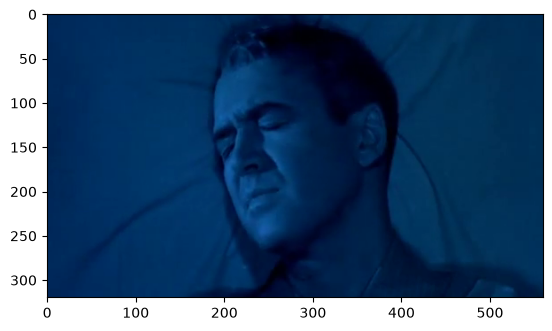

In [66]:
plt.imshow(image)

(np.float64(-0.5), np.float64(559.5), np.float64(319.5), np.float64(-0.5))

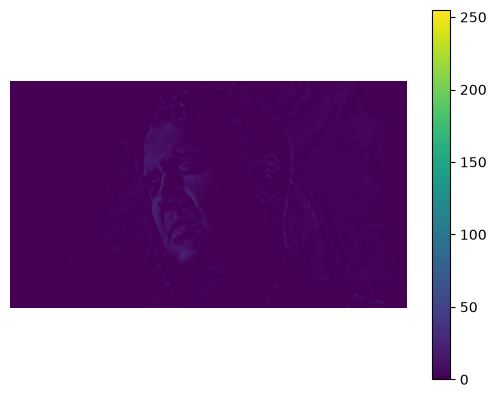

In [67]:
import matplotlib.pyplot as plt

plt.imshow(image[:,:,0], vmin=0, vmax=255)
plt.colorbar()
#plt.show()  
plt.gca().axis('off')

## 1.2 Extract the gallery

In [68]:
import numpy as np 
gallery_size = 150 
target_times_s = np.linspace(2.0, duration_s- 2.0, gallery_size) 
gallery = [] 
next_target = 0 
with av.open(video_path) as container: 
    for frame_index, frame in enumerate(container.decode(video=0)): 
        if next_target == gallery_size: 
            break 
        timestamp_s = float(frame.time) 
        if timestamp_s >= target_times_s[next_target]: 
            image = frame.to_ndarray(format="rgb24") 
            gallery.append({ "gallery_id": f"vertigo_{next_target:03d}", "image": image, "frame_index": frame_index, "timestamp_s": timestamp_s, }) 
            next_target += 1

## 1.3 Create the query images

In [61]:
from PIL import Image

# 1. Whole-frame query: complete image from frame 356 (vertigo_020)
# Since the gallery list is ordered from 0 to 149, vertigo_020 is at index 20
whole_frame_query_np = gallery[20]["image"]
whole_frame_query = Image.fromarray(whole_frame_query_np)

# Define the crop box (left, top, right, bottom) as requested
crop_box = (160, 40, 360, 240)

In [62]:
# 2. In-gallery crop: cropped region from vertigo_020
in_gallery_crop = whole_frame_query.crop(crop_box)


In [63]:
# 3. Held-out crop: cropped region from frame 350, which is not in the gallery
with av.open(video_path) as container:
    for frame_index, frame in enumerate(container.decode(video=0)):
        if frame_index == 350:
            held_out_image = frame.to_ndarray(format="rgb24")
            held_out_crop = Image.fromarray(held_out_image).crop(crop_box)
            break

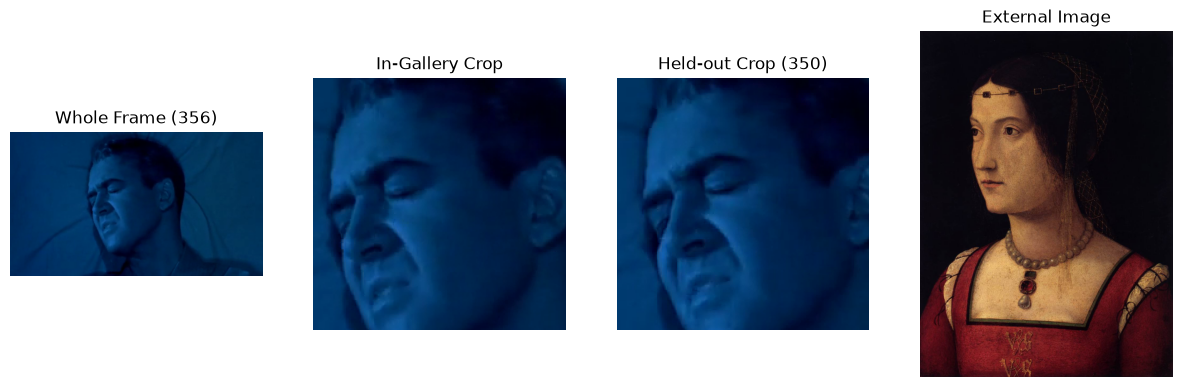

In [64]:
# 4. External image: Portrait of a Lady by Bernardino Zaganelli
try:
    external_image = Image.open("Portrait_of_a_Lady.jpg").convert("RGB")
except FileNotFoundError:
    print("Warning: Portrait_of_a_Lady.jpg not found. Please download it to proceed with Query 4.")

# Display them to verify
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 4, figsize=(15, 5))
axs[0].imshow(whole_frame_query); axs[0].set_title("Whole Frame (356)")
axs[1].imshow(in_gallery_crop); axs[1].set_title("In-Gallery Crop")
axs[2].imshow(held_out_crop); axs[2].set_title("Held-out Crop (350)")
if 'external_image' in locals():
    axs[3].imshow(external_image); axs[3].set_title("External Image")
for ax in axs:
    ax.axis('off')
plt.show()

## 1.4 Represent Images

### Implementation 1: Extracting the Global Color Histogram
For the color histogram, a standard approach in Image Mining is to compute a 3D joint histogram across the R, G, and B channels using NumPy. Normalizing the resulting histogram ensures that queries of different sizes (like the smaller cropped queries) can still be accurately compared against full gallery frames.

In [69]:
import numpy as np

def compute_color_histogram(image_np, bins_per_channel=8):
    """
    Computes a flattened, normalized 3D color histogram for an RGB image.
    Using 8 bins per channel results in an 8x8x8 = 512-dimensional vector.
    """
    # Reshape image from (H, W, 3) to a list of pixels (N, 3)
    pixels = image_np.reshape(-1, 3)
    
    # Compute 3D histogram
    hist, _ = np.histogramdd(
        pixels, 
        bins=[bins_per_channel, bins_per_channel, bins_per_channel], 
        range=[(0, 256), (0, 256), (0, 256)]
    )
    
    # Flatten to a 1D vector and normalize (L1 norm)
    hist = hist.flatten()
    if np.sum(hist) > 0:
        hist = hist / np.sum(hist)
        
    return hist

# Compute histograms for the entire gallery
color_hist_gallery_features = []
for item in gallery:
    hist = compute_color_histogram(item["image"])
    color_hist_gallery_features.append(hist)

# Convert to a single NumPy array of shape (150, 512)
color_hist_gallery_features = np.array(color_hist_gallery_features)
print(f"Color Histogram gallery features shape: {color_hist_gallery_features.shape}")

Color Histogram gallery features shape: (150, 512)


### Implementation2: Extracting the ResNet-50 Representation
The PDF provides the exact PyTorch boilerplate needed for this step. It replaces the final classification layer (model.fc) with an Identity layer, changing the output from 1,000 class logits to a raw 2,048-dimensional feature vector.

In [70]:
import torch
from PIL import Image
from torchvision.models import ResNet50_Weights, resnet50

# Load weights and preprocessing pipeline
weights = ResNet50_Weights.IMAGENET1K_V2
preprocess = weights.transforms()
model = resnet50(weights=weights)

# 1,000 logits -> 2,048-D representation
model.fc = torch.nn.Identity() 
model.eval()

batch_size = 16
gallery_embedding_batches = []

# Process the gallery in batches to optimize memory
with torch.inference_mode():
    for start in range(0, gallery_size, batch_size):
        print(f"Processing batch starting at {start} / {gallery_size}")
        
        # Convert RGB NumPy arrays to PIL Images, then apply ResNet preprocessing
        input_batch = torch.stack([
            preprocess(Image.fromarray(item["image"])) 
            for item in gallery[start : start + batch_size]
        ])
        
        # Pass batch through the model
        batch_embeddings = model(input_batch)
        gallery_embedding_batches.append(batch_embeddings)

# Concatenate all batches into a single tensor of shape (150, 2048)
resnet_gallery_features = torch.cat(gallery_embedding_batches)
print(f"ResNet gallery features shape: {resnet_gallery_features.shape}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /Users/sandyjingjing/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100.0%


Processing batch starting at 0 / 150
Processing batch starting at 16 / 150
Processing batch starting at 32 / 150
Processing batch starting at 48 / 150
Processing batch starting at 64 / 150
Processing batch starting at 80 / 150
Processing batch starting at 96 / 150
Processing batch starting at 112 / 150
Processing batch starting at 128 / 150
Processing batch starting at 144 / 150
ResNet gallery features shape: torch.Size([150, 2048])


### Optional representation: Hypothesis
**DINOv2** representations capture denser, more localized semantic features without being biased toward specific ImageNet classification categories. Therefore, **DINOv2** should perform significantly better than both ResNet-50 and color histograms on the external image query (identifying the semantic concept of a woman with a pendant) and the cropped queries, where spatial and semantic relationships matter more than global pixel distribution or object classes.

In [71]:
import torch
from torchvision import transforms
from PIL import Image

# Load the pretrained DINOv2 ViT-Small model from PyTorch Hub
dino_model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')
dino_model.eval()

# Standard preprocessing pipeline for DINOv2
dino_transform = transforms.Compose([
    transforms.Resize(256, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])

dino_gallery_batches = []
batch_size = 16

print("Extracting DINOv2 representations...")
with torch.inference_mode():
    for start in range(0, len(gallery), batch_size):
        input_batch = torch.stack([
            dino_transform(Image.fromarray(item["image"])) 
            for item in gallery[start : start + batch_size]
        ])
        
        # Extract features (resulting in a 384-dimensional vector per image for ViT-Small)
        batch_embeddings = dino_model(input_batch)
        dino_gallery_batches.append(batch_embeddings)

dino_gallery_features = torch.cat(dino_gallery_batches)
print(f"DINOv2 gallery features shape: {dino_gallery_features.shape}")

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /Users/sandyjingjing/.cache/torch/hub/main.zip


/Users/sandyjingjing/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/sandyjingjing/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/sandyjingjing/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
1.3%

Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /Users/sandyjingjing/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100.0%


Extracting DINOv2 representations...
DINOv2 gallery features shape: torch.Size([150, 384])
